### Imports and load dataset

In [1]:
#imports
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt



In [2]:
#loading the dataset
df = pd.read_csv("../data/raw/base_churn_pos_50k.csv", sep=",")

### Check the shape of the data

In [3]:

# shape
display(pd.DataFrame({
    "Lines": [df.shape[0]],
    "Columns": [df.shape[1]],
    "Duplicate Lines": [df.duplicated().sum()]
}))

# diagnose per column
summary = pd.DataFrame({
    "Type": df.dtypes.astype(str),
    "Nulls": df.isna().sum(),
    "Nulls (%)": df.isna().mean().mul(100)
})

display(
    summary.style
    .format({"Nulls": "{:,.0f}", "Nulls (%)": "{:.2f}%"})
    .background_gradient(subset=["Nulls (%)"], cmap="YlOrRd", vmin=0, vmax=100)
)

# Sample of the data
display(df.head())


,Lines,Columns,Duplicate Lines
0,529982,146,1329


,Type,Nulls,Nulls (%)
id_cliente,int64,0,0.00%
id_linha,int64,0,0.00%
data_corte,str,0,0.00%
churn_vol_30d,int64,0,0.00%
tipo_saida,str,"495,233",93.44%
data_churn,str,"495,233",93.44%
sistema_origem,str,0,0.00%
cod_lote_etl,int64,0,0.00%
pais,str,0,0.00%
data_ativacao,str,0,0.00%


,id_cliente,id_linha,data_corte,churn_vol_30d,tipo_saida,data_churn,sistema_origem,cod_lote_etl,pais,data_ativacao,...,ofertas_aceitas_12m,flag_oferta_recusada_recente,flag_usuario_app,logins_app_mes,variacao_logins_app,flag_consulta_saldo_ou_multa_no_app,promocao_concorrente_ddd,indice_agressividade_concorrentes_ddd,share_operadora_ddd,flag_consulta_portabilidade
0,10000000,20003079,2025-10-31,0,NaN,NaN,BSCS_legado,3325,BR,2019-11-15,...,0.0,0.0,0.0,0.0,NaN,0.0,1.0,62.0102,0.230629,0.0
1,10000001,20015702,2025-10-31,0,NaN,NaN,BSCS_legado,2713,BR,2015-10-20,...,0.0,0.0,1.0,0.0,-1.000000,0.0,1.0,50.7526,0.226816,0.0
2,10000002,20010056,2025-10-31,0,cancelamento,2026-03-09,BSCS_legado,2311,BR,2025-04-26,...,0.0,0.0,1.0,1.0,-0.800000,0.0,1.0,62.1070,0.237538,0.0
3,10000003,20002600,2025-10-31,0,NaN,NaN,BSCS_legado,273,BR,2022-10-17,...,0.0,0.0,1.0,8.0,0.043478,0.0,0.0,34.9984,0.266042,0.0
4,10000005,20023284,2025-10-31,0,NaN,NaN,BSCS_legado,727,BR,2023-10-20,...,0.0,0.0,0.0,0.0,NaN,0.0,0.0,38.0805,0.221200,0.0


### Identifying target variable

In [4]:
#identifying the target variable

target_variable = "churn_vol_30d"  

distribution = (
    df[target_variable].value_counts(dropna=False).rename_axis("Target Variable").reset_index(name="Count")
)

distribution['Percent'] = (distribution['Count'] / len(df) * 100).round(2)

display(distribution)

,Target Variable,Count,Percent
0,0,524023,98.88
1,1,5959,1.12


In [5]:
#- The data set is skewed, as there are few cases of churn compared to retention

#monthly churn 

monthly_group = df['churn_vol_30d'].groupby(df['data_corte'])
monthly_total = monthly_group.size()
monthly_churn =  monthly_group.sum()
monthly_churn_rate = (monthly_group.sum() / monthly_group.size()) *100

monthly_churn_summary = pd.DataFrame({
    "Total": monthly_total,
    "Churns": monthly_churn,
    "Churns %": monthly_churn_rate
})

display(monthly_churn_summary)




,Total,Churns,Churns %
data_corte,,,
2025-10-31,43989,589,1.338971
2025-11-30,43985,595,1.352734
2025-12-31,43940,485,1.103778
2026-01-31,44046,601,1.364483
2026-02-28,43985,614,1.395930
2026-03-31,43905,500,1.138822
2026-04-30,44002,424,0.963593
2026-05-31,44138,372,0.842811
2026-06-30,44347,426,0.960606


### Remove duplicates

In [6]:
#remove duplicates

df_without_duplicates = df.drop_duplicates()

### Fixing Types

In [7]:
#fixing types

df_clean = df_without_duplicates.copy()

dictionary = pd.read_csv("../data/raw/base_churn_pos_50k_dicionario.csv")

# Create a map: column name → dictionary type
type_mapping = dictionary.set_index("coluna")["tipo"].to_dict() #select tipo and convert result, originally Series, into a dict

# Adapts data types to accept null values in pandas (nullable values)
# Acept null values means: a column may contain values of the defined type and missing values, without needing to switch to another type
pandas_types = {
    "str": "string",
    "int64": "Int64",
    "float64": "Float64"
}

#Create a new dictionary containing the type_mapping entries whose columns exist in df_clean. 
#For each type, if it is a key in `pandas_types`, replace it with the corresponding value; otherwise, retain the original type.
new_mapping = {}

for column, dtype in type_mapping.items():
    if column in df_clean.columns:
        adapted_type = pandas_types.get(dtype, dtype)
        new_mapping[column] = adapted_type

#the result is a new dict with fixed types
fixed_type_mapping = new_mapping

# Define the data columns and formats
date_columns = ["data_corte", "data_churn", "data_ativacao"]

date_formats = {
    "data_corte": "%Y-%m-%d",  # Ex.: 2025-10-31
    "data_churn": "%d/%m/%Y"   # Ex.: 23/02/2024
}

for column, date_format in date_formats.items():
    df_clean[column] = pd.to_datetime(
        df_clean[column],
        format="ISO8601",
        errors="raise"
    )

for column, dtype in fixed_type_mapping.items():
    try:
        if column in date_columns:
            continue
        df_clean[column].astype(dtype)
    except Exception as e:
        print(f'Erro na conversão da coluna: {column}')
        print(e)
     
    
display(df_clean.dtypes.to_frame("Type after conversion"))

,Type after conversion
id_cliente,int64
id_linha,int64
data_corte,datetime64[us]
churn_vol_30d,int64
tipo_saida,str
...,...
flag_consulta_saldo_ou_multa_no_app,float64
promocao_concorrente_ddd,float64
indice_agressividade_concorrentes_ddd,float64
share_operadora_ddd,float64


### Handling Null Values

In [8]:
pd.crosstab(
    df_clean["dias_ate_resolucao_ultima_ordem"].isna(),
    df_clean["ordens_de_reparo_abertas"] > 0,
    margins=True
)

ordens_de_reparo_abertas,False,True,All
dias_ate_resolucao_ultima_ordem,,,
False,101443,24068,125511
True,402844,298,403142
All,504287,24366,528653


In [9]:
#variable: dias_ate_resolucao_ultima_ordem

#there are clients where dias_ate_resolucao_ultima_ordem is null
#but this variable can help the model learn separatedly: 
# a) effect of time resolution
# b) effect of non history 
# e.g.: clients without dias_ate_resolucao_ultima_ordem can have higher risks for churn
df_clean["dias_ate_resolucao_ultima_ordem_missing"] = (
    df_clean["dias_ate_resolucao_ultima_ordem"]
    .isna()
    .astype("Int64")
)

dias_ate_resolucao_ultima_ordem_median = df_clean["dias_ate_resolucao_ultima_ordem"].median()

df_clean["dias_ate_resolucao_ultima_ordem"] = (
    df_clean["dias_ate_resolucao_ultima_ordem"]
    .fillna(dias_ate_resolucao_ultima_ordem_median)
)



In [10]:
#variable: meses_ate_fim_fidelidade
#it is possible that the client does not have a fidelity plan, that's why there is a lot of null values

pd.crosstab(
    df_clean["meses_ate_fim_fidelidade"].isna(),
    df_clean["fidelidade_ativa"],
    margins=True
)

#solution: fill the null values with 0, because our model does not accept NaN values
# 0 means: this client has no fidelity plan
df_clean["meses_ate_fim_fidelidade"] = (
    df_clean["meses_ate_fim_fidelidade"].fillna(0)
)


In [11]:
#variable: meses_desde_fim_fidelidade
#it is possible that the client never had a fidelity plan or it has one right now, that's why there is a lot of null values

pd.crosstab(df_clean["meses_desde_fim_fidelidade"].isna(), df_clean["fidelidade_ativa"])

#solution: create a flag for separating clients who never had a fidelity plan or it has one right now
df_clean["meses_desde_fim_fidelidade_missing"] = (
    df_clean["meses_desde_fim_fidelidade"]
    .isna()
    .astype("Int64")
)

#if model does not accept null values
df_clean["meses_desde_fim_fidelidade"] = (
    df_clean["meses_desde_fim_fidelidade"].fillna(0)
)


In [12]:
#variable: meses_desde_fim_desconto

#solution: create a flag for separating clients who ever had a discount
df_clean["meses_desde_fim_desconto_missing"] = (
    df_clean["meses_desde_fim_desconto"]
    .isna()
    .astype("Int64")
)

#and input 0 if there was no discount recorded
df_clean["meses_desde_fim_desconto"] = (
    df_clean["meses_desde_fim_desconto"].fillna(0)
    
)

In [13]:
#variable: csat_ultimo_contato, nps
#there are clients who does not answer to feedback surveys after atendimentos
# or never answer to nps surveys
# we need to differentiate them using flags AND inputind a median value

df_clean["csat_ultimo_contato_missing"] = (
    df_clean["csat_ultimo_contato"]
    .isna()
    .astype("Int64")
)

csat_median = df_clean["csat_ultimo_contato"].median()

df_clean["csat_ultimo_contato"] = (
    df_clean["csat_ultimo_contato"]
    .fillna(csat_median)
)

df_clean["nps_missing"] = (
    df_clean["nps"]
    .isna()
    .astype("Int64")
)

nps_median = df_clean["nps"].median()

df_clean["nps"] = (
    df_clean["nps"]
    .fillna(nps_median)
)




In [14]:
#variable: pct_reajuste_ultimo
# it is a critical variable. Its absence can indicate that there was no adjusment or it was not collected
#solution: creat a flag indication the value is missing AND filling NaN with 0

df_clean["pct_reajuste_ultimo_missing"] = (
    df_clean["pct_reajuste_ultimo"]
    .isna()
    .astype("Int64")
)

df_clean["pct_reajuste_ultimo"] = (
    df_clean["pct_reajuste_ultimo"].fillna(0)
)


In [15]:
#variable: dados_gb_wifi_offload
# it is a critical variable. High levels can indicate that the user does not need an abonnement anymore
#solution: creat a flag indication the value is missing and input the median value

df_clean["dados_gb_wifi_offload_missing"] = (
    df_clean["dados_gb_wifi_offload"]
    .isna()
    .astype("Int64")
)

mediana = df_clean["dados_gb_wifi_offload"].median()

df_clean["dados_gb_wifi_offload"] = (
    df_clean["dados_gb_wifi_offload"]
    .fillna(mediana)
)

In [16]:
#variable: distancia_ao_segmento

df_clean["distancia_ao_segmento_missing"] = (
    df_clean["distancia_ao_segmento"]
    .isna()
    .astype("Int64")
)

mediana = df_clean["distancia_ao_segmento"].median()

df_clean["distancia_ao_segmento"] = (
    df_clean["distancia_ao_segmento"].fillna(mediana)
)

In [17]:
#variable: variacao_logins_app

df_clean["variacao_logins_app_missing"] = (
    df_clean["variacao_logins_app"]
    .isna()
    .astype("Int64")
)

variacao_logins_app_median = df_clean["variacao_logins_app"].median()

df_clean["variacao_logins_app"] = (
    df_clean["variacao_logins_app"]
    .fillna(variacao_logins_app_median)
)

In [18]:
#variable: tempo_resolucao_medio

df_clean["tempo_resolucao_medio_missing"] = (
    df_clean["tempo_resolucao_medio"]
    .isna()
    .astype("Int64")
)

tempo_resolucao_medio_median = df_clean["tempo_resolucao_medio"].median()

df_clean["tempo_resolucao_medio"] = (
    df_clean["tempo_resolucao_medio"]
    .fillna(tempo_resolucao_medio_median)
)

### Shape after fix null types

In [19]:

# shape
display(pd.DataFrame({
    "Lines": [df_clean.shape[0]],
    "Columns": [df_clean.shape[1]],
    "Duplicate Lines": [df_clean.duplicated().sum()]
}))

# diagnose per column
summary = pd.DataFrame({
    "Type": df_clean.dtypes.astype(str),
    "Nulls": df_clean.isna().sum(),
    "Nulls (%)": df_clean.isna().mean().mul(100)
})

display(
    summary.style
    .format({"Nulls": "{:,.0f}", "Nulls (%)": "{:.2f}%"})
    .background_gradient(subset=["Nulls (%)"], cmap="YlOrRd", vmin=0, vmax=100)
)

# Sample of the data
display(df_clean.head())


,Lines,Columns,Duplicate Lines
0,528653,156,0


,Type,Nulls,Nulls (%)
id_cliente,int64,0,0.00%
id_linha,int64,0,0.00%
data_corte,datetime64[us],0,0.00%
churn_vol_30d,int64,0,0.00%
tipo_saida,str,"494,003",93.45%
data_churn,datetime64[us],"494,003",93.45%
sistema_origem,str,0,0.00%
cod_lote_etl,int64,0,0.00%
pais,str,0,0.00%
data_ativacao,str,0,0.00%


,id_cliente,id_linha,data_corte,churn_vol_30d,tipo_saida,data_churn,sistema_origem,cod_lote_etl,pais,data_ativacao,...,dias_ate_resolucao_ultima_ordem_missing,meses_desde_fim_fidelidade_missing,meses_desde_fim_desconto_missing,csat_ultimo_contato_missing,nps_missing,pct_reajuste_ultimo_missing,dados_gb_wifi_offload_missing,distancia_ao_segmento_missing,variacao_logins_app_missing,tempo_resolucao_medio_missing
0,10000000,20003079,2025-10-31,0,NaN,NaT,BSCS_legado,3325,BR,2019-11-15,...,1,0,0,1,1,1,1,0,1,1
1,10000001,20015702,2025-10-31,0,NaN,NaT,BSCS_legado,2713,BR,2015-10-20,...,1,0,0,0,1,0,0,0,0,0
2,10000002,20010056,2025-10-31,0,cancelamento,2026-03-09,BSCS_legado,2311,BR,2025-04-26,...,1,1,1,0,1,1,1,0,0,0
3,10000003,20002600,2025-10-31,0,NaN,NaT,BSCS_legado,273,BR,2022-10-17,...,0,1,0,1,1,0,1,0,0,0
4,10000005,20023284,2025-10-31,0,NaN,NaT,BSCS_legado,727,BR,2023-10-20,...,0,1,1,1,1,1,1,0,1,1


### Split of data: training and test

In [20]:
X = df_clean.drop(columns='churn_vol_30d')
y = df_clean['churn_vol_30d']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42, #aleatoriedade reproduzível.
    stratify=y # It maintains the same proportion of classes in the training and test sets.
)

#### Target analysis

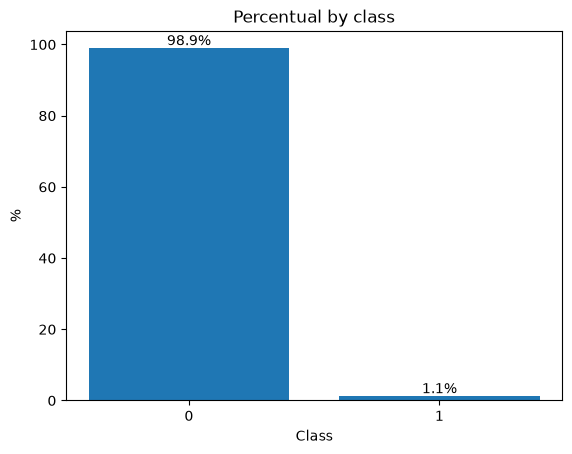

In [21]:
# Count and percentage for each class (value_counts(normalise=True)) 

total_classes = y_train.value_counts(normalize=True).sort_index() * 100
classes = total_classes.index.astype(str)
percentages = total_classes.to_numpy(dtype=float)

bars = plt.bar(classes, percentages)
plt.bar_label(bars, fmt="%.1f%%")
plt.xlabel("Class")
plt.ylabel("%")
plt.title("Percentual by class")
plt.show()

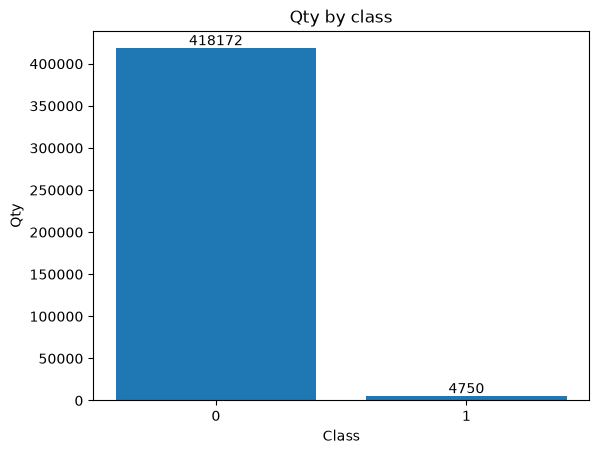

In [22]:

# Bar chart showing the distribution of grades 

total_classes = y_train.value_counts().sort_index()
classes = total_classes.index.astype(str)
counts = total_classes.to_numpy(dtype=float)

bars = plt.bar(classes, counts)
plt.bar_label(bars, fmt="%.0f")

plt.xlabel("Class")
plt.ylabel("Qty")
plt.title("Qty by class")
plt.show()



#### Num var analysis

In [40]:
#numerical var analysis

#what num columns do we have?
num_cols = df_clean.select_dtypes(include=["number"]).drop(columns=["id_cliente", "id_linha", "cod_lote_etl", "ddd"]).columns
pd.reset_option("display.max_rows")
pd.DataFrame(num_cols)



,0
0,churn_vol_30d
1,tenure_meses
2,idade
3,qtd_linhas_titular
4,flag_dependente
...,...
126,pct_reajuste_ultimo_missing
127,dados_gb_wifi_offload_missing
128,distancia_ao_segmento_missing
129,variacao_logins_app_missing


In [ ]:
pd.set_option("display.max_rows", None)
df_clean[num_cols].describe().T #T

# col = "parcelas_restantes_aparelho"
# analysis = df_clean[col].value_counts().sort_index().head(10)
# pd.DataFrame(analysis)
#df_clean["idade"].value_counts().sort_index().tail(10)

#idade: 0 and 150 age?
#tenure_meses: min negative?
#qtd_linhas_titular: max 60?
#supicious_variables = ["idade"]
#desconto_promocional,dados_gb_mes,minutos_voz_total, minutos_on_net, minutos_fixo, minutos_offnet: valor negativo?

# qtd_chamadas: valor max 6262 estranho
# duracao_media_chamada: valor negativo
# dados_inclinacao_6m: o que é?

# voz_media_3m
# voz_media_6m
# voz_razao_mes_vs_media_3m
# voz_inclinacao_6m

# dias_uso_inclinacao_6m: o que é?


,count,mean,std,min,25%,50%,75%,max
churn_vol_30d,528653.0,0.01123,0.105377,0.0,0.0,0.0,0.0,1.0
tenure_meses,527079.0,41.924199,39.462002,-12.0,17.0,30.0,53.0,222.0
idade,511320.0,43.584077,14.524941,0.0,33.0,43.0,53.0,150.0
qtd_linhas_titular,527068.0,2.079603,2.348035,1.0,1.0,1.0,2.0,60.0
flag_dependente,527021.0,0.215731,0.411329,0.0,0.0,0.0,0.0,1.0
flag_outras_linhas_ja_sairam,527050.0,0.020825,0.142799,0.0,0.0,0.0,0.0,1.0
valor_plano,527652.0,81.771285,41.936524,0.0,55.75,68.16,94.98,275.01
franquia_gb,527578.0,37.98009,42.83477,5.0,15.0,20.0,50.0,200.0
flag_5g,527566.0,0.45915,0.498329,0.0,0.0,0.0,1.0,1.0
flag_combo_fibra,527630.0,0.247323,0.431456,0.0,0.0,0.0,0.0,1.0


In [ ]:
pd.reset_option("display.max_rows")